# VeriCred — YOLO Forgery-Region Training

Environment-agnostic (local GPU, Colab, or CPU smoke test). No Colab-only APIs.
Dataset lives at `../d1Certificate_forgery_detection/data.yaml` relative to this notebook.

**Training requirements:** a real run needs a GPU (local CUDA or Colab GPU).
CPU is only for smoke testing (1-3 epochs, `yolo11n.pt`). A full CPU run is not practical.
Output `best.pt` goes to project `weights/` (gitignored).

In [4]:
# 0. Setup: resolve dataset path + verify expectations (fails loudly)
from pathlib import Path
import yaml

try:
    NB_DIR = Path(__file__).resolve().parent  # script context
except NameError:
    NB_DIR = Path.cwd()  # notebook: kernel cwd is the notebook dir
DS = (NB_DIR / "../d1Certificate_forgery_detection").resolve()
assert (DS / "data.yaml").exists(), f"data.yaml missing under {DS}"
cfg = yaml.safe_load(open(DS / "data.yaml"))
assert cfg["nc"] == 2, cfg
assert list(cfg["names"]) == ["fake", "true"], cfg["names"]  # 0=fake, 1=true

for split, n_img in [("train", 183), ("valid", 31), ("test", 40)]:
    imgs = list((DS / split / "images").glob("*"))
    lbls = list((DS / split / "labels").glob("*.txt"))
    assert len(imgs) == n_img, (split, len(imgs))
    assert len(lbls) == n_img, (split, len(lbls))
    assert {p.stem for p in imgs} == {p.stem for p in lbls}, f"stem mismatch in {split}"
print("dataset OK:", DS)
print("classes:", cfg["names"])
DATA_YAML = str(DS / "data.yaml")

dataset OK: /home/donuts/VeriCred/d1Certificate_forgery_detection
classes: ['fake', 'true']


In [5]:
import sys
print(sys.executable)

import torch
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

from ultralytics import YOLO
print("Ultralytics: OK")

/home/donuts/VeriCred/.venv/bin/python
PyTorch: 2.4.1+cu124
CUDA: True
Ultralytics: OK


In [6]:
print("DATA_YAML:", DATA_YAML)
print("DEVICE:", DEVICE)

DATA_YAML: /home/donuts/VeriCred/d1Certificate_forgery_detection/data.yaml


NameError: name 'DEVICE' is not defined

In [7]:
# 1. Device: CUDA -> MPS -> CPU (informational; Ultralytics picks device too)
import torch

if torch.cuda.is_available():
    DEVICE = 0
    print("CUDA GPU:", torch.cuda.get_device_name(0))
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"
    print("Apple MPS device")
else:
    DEVICE = "cpu"
    print("CPU only: use SMOKE_TEST (below). A full training run on CPU is not practical.")

CUDA GPU: NVIDIA GeForce GTX 1650


In [8]:
# 2. Train: yolo11s default; fall back to yolo11n on GPU OOM
from ultralytics import YOLO

SMOKE_TEST = False  # set True for a 1-epoch CPU sanity check
BASE = "yolo11s.pt"   # fallback: "yolo11n.pt" if GPU memory is insufficient
EPOCHS = 1 if SMOKE_TEST else 50

model = YOLO(BASE)
try:
    model.train(data=DATA_YAML, epochs=EPOCHS, imgsz=640, device=DEVICE)
except torch.cuda.OutOfMemoryError:
    print("OOM on", BASE, "-> retrying with yolo11n.pt")
    torch.cuda.empty_cache()
    model = YOLO("yolo11n.pt")
    model.train(data=DATA_YAML, epochs=EPOCHS, imgsz=640, device=DEVICE)

Ultralytics 8.4.165 🚀 Python-3.12.3 torch-2.4.1+cu124 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/donuts/VeriCred/d1Certificate_forgery_detection/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=

In [9]:
# 3. Evaluate on valid + test (report mAP50 / mAP50-95 per class)
print("--- valid ---")
print(model.val(data=DATA_YAML, split="val"))
print("--- test ---")
print(model.val(data=DATA_YAML, split="test"))  # record mAP50, mAP50-95 honestly

--- valid ---
Ultralytics 8.4.165 🚀 Python-3.12.3 torch-2.4.1+cu124 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2221.7±866.7 MB/s, size: 61.8 KB)
val: Scanning /home/donuts/VeriCred/d1Certificate_forgery_detection/valid/labels.cache... 31 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 10.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.2it/s 1.6s3.4s
                   all         31         93      0.998          1      0.995      0.762
                  fake         26         54      0.999          1      0.995       0.75
                  true         20         39      0.998          1      0.995      0.775
Speed: 5.3ms preprocess, 24.4ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /home/donuts/VeriCred/runs/detect/val
ultralytics.utils.metr

In [10]:
# 4. Export best.pt to project weights/ (gitignored; inference reads it via VERICRED_WEIGHTS or weights/best.pt)
import shutil
from pathlib import Path

src = Path(model.trainer.save_dir) / "weights" / "best.pt"
dst = Path("../weights/best.pt").resolve()
dst.parent.mkdir(exist_ok=True)
shutil.copy(src, dst)
print("saved:", dst, f"({dst.stat().st_size / 1e6:.1f} MB, gitignored, do not commit)")

saved: /home/donuts/VeriCred/weights/best.pt (19.2 MB, gitignored, do not commit)


In [11]:
from ultralytics import YOLO
from pathlib import Path

# Load the trained model
model = YOLO("../weights/best.pt")

# Run inference on the test images
test_dir = Path("../d1Certificate_forgery_detection/test/images")

results = model.predict(
    source=str(test_dir),
    imgsz=640,
    conf=0.25,
    save=True
)

print(f"Tested {len(results)} images")


image 1/40 /home/donuts/VeriCred/notebooks/../d1Certificate_forgery_detection/test/images/Upto-4th-Sem-Markscard_page-0002_jpg.rf.21d731585a496c387ab1af211f6dce61.jpg: 640x640 3 trues, 19.1ms
image 2/40 /home/donuts/VeriCred/notebooks/../d1Certificate_forgery_detection/test/images/Upto-4th-Sem-Markscard_page-0002_jpg.rf.3629297669b914c5914607309d50d2a2.jpg: 640x640 3 trues, 28.6ms
image 3/40 /home/donuts/VeriCred/notebooks/../d1Certificate_forgery_detection/test/images/Upto-4th-Sem-Markscard_page-0002_jpg.rf.67bbb17264bfb12640e7874929600ea7.jpg: 640x640 3 trues, 19.4ms
image 4/40 /home/donuts/VeriCred/notebooks/../d1Certificate_forgery_detection/test/images/Upto-4th-Sem-Markscard_page-0002_jpg.rf.8683bd9b5db9b70f7b13eafdc0f8972c.jpg: 640x640 3 trues, 19.2ms
image 5/40 /home/donuts/VeriCred/notebooks/../d1Certificate_forgery_detection/test/images/Upto-4th-Sem-Markscard_page-0002_jpg.rf.8777eae35fbe04bb0e47668577e7e78e.jpg: 640x640 3 trues, 23.9ms
image 6/40 /home/donuts/VeriCred/notebo

f4_png.rf.83af655c4721072cda4d4c02798c0f9a.jpg


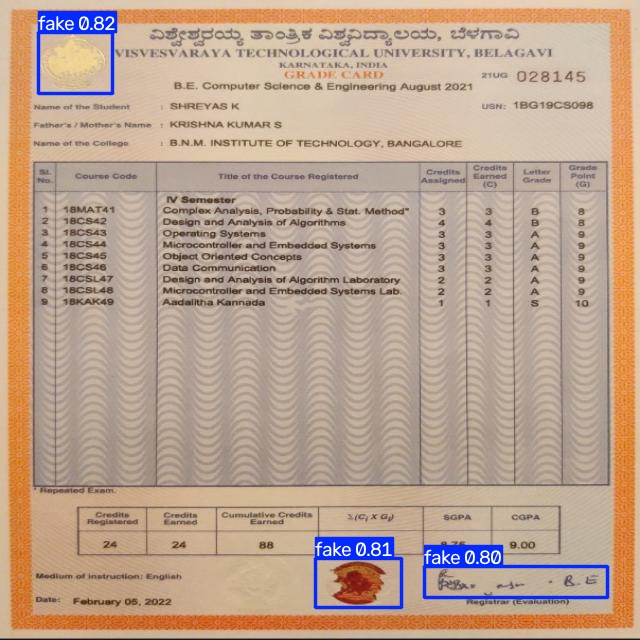

f5_jpg.rf.61deedbc33455340876f451f5ce2c32a.jpg


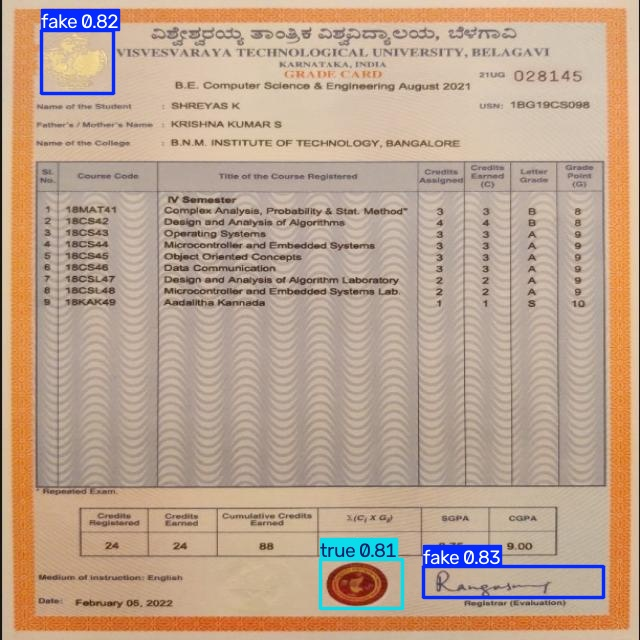

f6_jpg.rf.b0d776c22b761efb5940f0ea0ac3bfe8.jpg


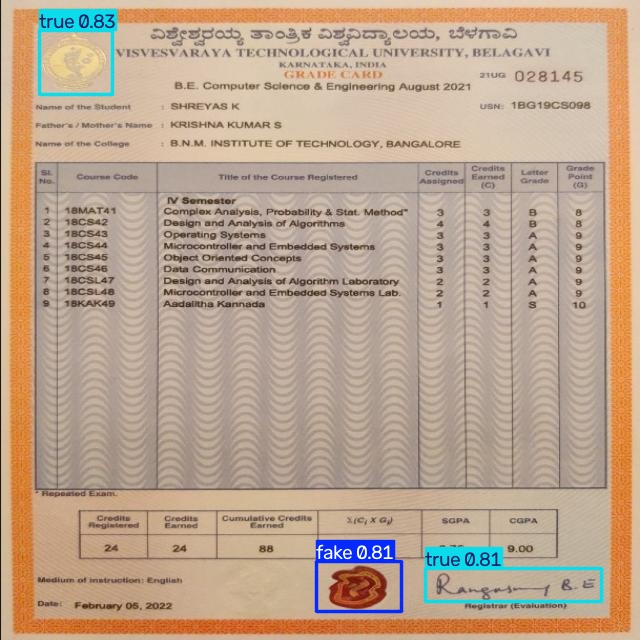

fnew2_png.rf.5cabad9cacef23e6bad33c06b84d32a1.jpg


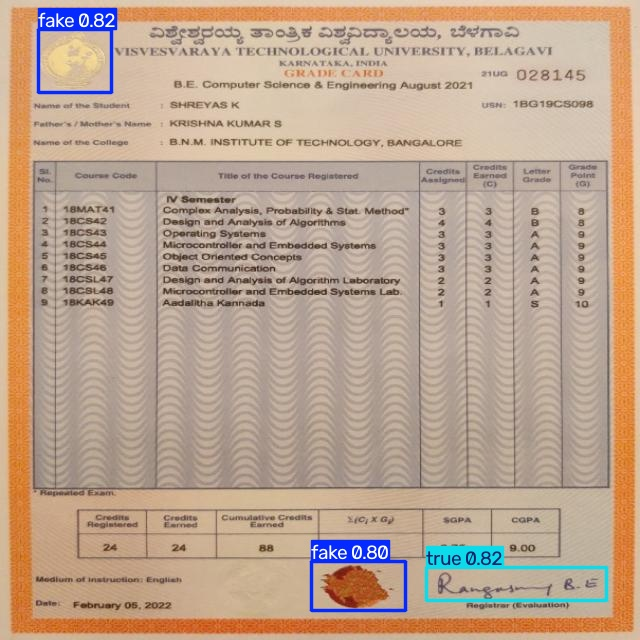

In [12]:
from IPython.display import display
from PIL import Image
from pathlib import Path

pred_dir = Path("../runs/detect/predict")

samples = [
    "f4_png.rf.83af655c4721072cda4d4c02798c0f9a.jpg",
    "f5_jpg.rf.61deedbc33455340876f451f5ce2c32a.jpg",
    "f6_jpg.rf.b0d776c22b761efb5940f0ea0ac3bfe8.jpg",
    "fnew2_png.rf.5cabad9cacef23e6bad33c06b84d32a1.jpg",
]

for name in samples:
    path = pred_dir / name
    print(name)
    display(Image.open(path))